# Smart Customer Churn & Retention Intelligence System

## Project objective
Build an end-to-end churn prediction and retention prioritisation workflow. This version replaces the earlier weak 1,000-row random dataset with a larger, reproducible **12,000-customer synthetic telecom-style dataset** whose churn outcomes are probabilistically generated from customer tenure, contract, service experience, payment behaviour and engagement signals.

**Important data disclosure:** This is simulated data, not a real telecom company's customer records. The notebook is suitable for demonstrating the workflow and model evaluation, but its scores must not be presented as performance on real customers. For a production or stronger portfolio validation, repeat the experiment on a documented real dataset such as IBM's public Telco Customer Churn sample.

### What this notebook includes
- 12,000 simulated customer records with realistic feature relationships and a non-deterministic churn target.
- Exploratory analysis and data-quality checks.
- Stratified train / validation / test split.
- Logistic Regression, Random Forest and CatBoost comparison.
- Model selection using validation PR-AUC.
- Threshold selection using validation data only, prioritising accuracy while requiring at least 65% churn recall.
- Final evaluation on an untouched test set.
- Customer-level churn probabilities, risk categories, retention actions and CSV export.

## 1. Install and import libraries
If CatBoost is not installed, run `pip install catboost` in your environment, then restart the kernel.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay
)
from catboost import CatBoostClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

print("Libraries imported successfully.")
print("Pandas:", pd.__version__)

Libraries imported successfully.
Pandas: 2.2.3


## 2. Create the customer dataset
The synthetic data contains a mix of numerical and categorical variables. Churn is generated from a probability model with realistic directional relationships, then sampled probabilistically so the target is not a simple deterministic rule.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n_customers = 12000

tenure = rng.integers(1, 73, n_customers)
monthly_charges = rng.normal(78, 25, n_customers).clip(20, 125)
contract_type = rng.choice(["Month-to-month", "One year", "Two year"], n_customers, p=[0.55, 0.27, 0.18])
support_tickets = rng.poisson(1.3, n_customers).clip(0, 8)
late_payments = rng.poisson(0.7, n_customers).clip(0, 5)
customer_satisfaction = rng.normal(7.2, 1.5, n_customers).clip(1, 10)
service_downtime_hours = rng.gamma(1.4, 1.8, n_customers).clip(0, 15)
monthly_usage_hours = rng.normal(90, 25, n_customers).clip(5, 180)
usage_decline_flag = rng.binomial(1, 0.18, n_customers)
autopay_enabled = rng.binomial(1, 0.62, n_customers)
active_addon_count = rng.integers(0, 7, n_customers)

# Churn propensity: higher support/payment friction and weaker engagement increase risk.
churn_logit = (
    -3.0
    + 0.10 * np.maximum(18 - tenure, 0)
    + 1.40 * (contract_type == "Month-to-month")
    + 0.70 * (contract_type == "One year")
    + 0.70 * support_tickets
    + 0.75 * late_payments
    - 0.75 * (customer_satisfaction - 6)
    + 0.18 * service_downtime_hours
    - 0.018 * (monthly_usage_hours - 80)
    + 1.10 * usage_decline_flag
    - 0.75 * autopay_enabled
    - 0.20 * active_addon_count
    + 0.50 * ((contract_type == "Month-to-month") & (tenure < 12))
)
churn_probability = 1 / (1 + np.exp(-churn_logit))
churn = rng.binomial(1, churn_probability)

data = pd.DataFrame({
    "customer_id": [f"TEL{idx:06d}" for idx in range(1, n_customers + 1)],
    "tenure_months": tenure,
    "monthly_charges": monthly_charges.round(2),
    "contract_type": contract_type,
    "support_tickets": support_tickets,
    "late_payments": late_payments,
    "customer_satisfaction": customer_satisfaction.round(1),
    "service_downtime_hours": service_downtime_hours.round(2),
    "monthly_usage_hours": monthly_usage_hours.round(1),
    "usage_decline_flag": usage_decline_flag,
    "autopay_enabled": autopay_enabled,
    "active_addon_count": active_addon_count,
    "churn": churn
})

print("Dataset created successfully.")
print("Rows:", data.shape[0], "| Columns:", data.shape[1])
print("Churn rate: {:.2f}%".format(data["churn"].mean() * 100))
display(data.head())

Dataset created successfully.
Rows: 12000 | Columns: 13
Churn rate: 23.48%


,customer_id,tenure_months,monthly_charges,contract_type,support_tickets,late_payments,customer_satisfaction,service_downtime_hours,monthly_usage_hours,usage_decline_flag,autopay_enabled,active_addon_count,churn
0,TEL000001,7,52.08,Month-to-month,2,0,5.3,7.68,115.9,0,1,6,1
1,TEL000002,56,90.07,One year,0,0,6.9,1.21,134.3,1,1,2,0
2,TEL000003,48,62.81,Month-to-month,1,1,9.6,9.32,64.7,1,1,5,1
3,TEL000004,32,36.77,Month-to-month,2,0,5.3,1.55,96.4,0,1,2,0
4,TEL000005,32,70.81,One year,2,0,5.1,2.36,77.3,0,1,0,0


## 3. Data quality and exploratory analysis

In [3]:
print("DATA QUALITY SUMMARY")
print("-" * 45)
print("Shape:", data.shape)
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate customer IDs:", data["customer_id"].duplicated().sum())
print("Missing values:")
display(data.isna().sum().to_frame("Missing values"))
print("\nTarget distribution:")
target_summary = data["churn"].value_counts().rename(index={0: "Retained", 1: "Churned"}).to_frame("Customers")
target_summary["Percentage"] = (target_summary["Customers"] / len(data) * 100).round(2)
display(target_summary)

DATA QUALITY SUMMARY
---------------------------------------------
Shape: (12000, 13)
Duplicate rows: 0
Duplicate customer IDs: 0
Missing values:


,Missing values
customer_id,0
tenure_months,0
monthly_charges,0
contract_type,0
support_tickets,0
late_payments,0
customer_satisfaction,0
service_downtime_hours,0
monthly_usage_hours,0
usage_decline_flag,0



Target distribution:


,Customers,Percentage
churn,,
Retained,9182,76.52
Churned,2818,23.48


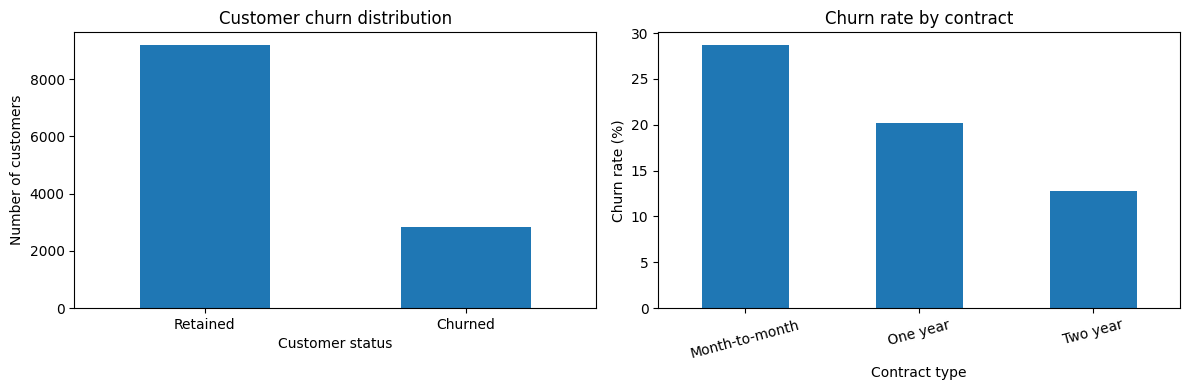

Average customer metrics by churn outcome:


,tenure_months,monthly_charges,support_tickets,late_payments,customer_satisfaction,service_downtime_hours,monthly_usage_hours
churn,,,,,,,
Retained,37.62,77.99,1.15,0.62,7.41,2.36,91.64
Churned,32.10,77.41,1.79,0.99,6.34,2.93,84.80


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target_summary["Customers"].plot(kind="bar", ax=axes[0], title="Customer churn distribution")
axes[0].set_xlabel("Customer status")
axes[0].set_ylabel("Number of customers")
axes[0].tick_params(axis="x", rotation=0)
(data.groupby("contract_type")["churn"].mean().sort_values(ascending=False) * 100).plot(kind="bar", ax=axes[1], title="Churn rate by contract")
axes[1].set_xlabel("Contract type")
axes[1].set_ylabel("Churn rate (%)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

print("Average customer metrics by churn outcome:")
display(data.groupby("churn")[["tenure_months", "monthly_charges", "support_tickets", "late_payments", "customer_satisfaction", "service_downtime_hours", "monthly_usage_hours"]].mean().round(2).rename(index={0: "Retained", 1: "Churned"}))

## 4. Prepare features and split the data
The customer ID is excluded from model training. The dataset is split into 70% training, 15% validation and 15% final test data. The test set remains untouched until final evaluation.

In [5]:
X = data.drop(columns=["customer_id", "churn"])
y = data["churn"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("TRAINING ROWS:", len(X_train))
print("VALIDATION ROWS:", len(X_valid))
print("FINAL TEST ROWS:", len(X_test))
print("Train churn rate: {:.2f}%".format(y_train.mean() * 100))
print("Validation churn rate: {:.2f}%".format(y_valid.mean() * 100))
print("Test churn rate: {:.2f}%".format(y_test.mean() * 100))

TRAINING ROWS: 8400
VALIDATION ROWS: 1800
FINAL TEST ROWS: 1800
Train churn rate: 23.49%
Validation churn rate: 23.50%
Test churn rate: 23.44%


## 5. Build preprocessing and candidate models
CatBoost can process categorical columns directly. Logistic Regression and Random Forest use one-hot encoding and numeric scaling. All preprocessing is fitted only on training data through pipelines.

In [6]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
        ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
    ]
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=350, max_depth=14, min_samples_leaf=4,
        random_state=RANDOM_STATE, n_jobs=-1, class_weight="balanced_subsample"
    ))
])

catboost_model = CatBoostClassifier(
    iterations=1200, depth=6, learning_rate=0.035,
    loss_function="Logloss", eval_metric="AUC",
    l2_leaf_reg=5, random_seed=RANDOM_STATE,
    verbose=False, allow_writing_files=False
)

print("Candidate models prepared:")
print("1. Logistic Regression")
print("2. Random Forest")
print("3. CatBoost Classifier")

Candidate models prepared:
1. Logistic Regression
2. Random Forest
3. CatBoost Classifier


## 6. Train models and compare validation performance
Model selection is based on validation Average Precision (PR-AUC), which is useful when churners are the minority class. Accuracy alone can hide missed churners.

In [7]:
logistic_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)
catboost_model.fit(
    X_train, y_train,
    cat_features=categorical_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    verbose=False
)

candidate_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "CatBoost": catboost_model
}

validation_rows = []
validation_probabilities = {}
for model_name, model in candidate_models.items():
    probabilities = model.predict_proba(X_valid)[:, 1]
    validation_probabilities[model_name] = probabilities
    validation_rows.append({
        "Model": model_name,
        "Validation Accuracy (0.50)": accuracy_score(y_valid, probabilities >= 0.50),
        "Validation ROC-AUC": roc_auc_score(y_valid, probabilities),
        "Validation PR-AUC": average_precision_score(y_valid, probabilities)
    })

validation_comparison = pd.DataFrame(validation_rows).sort_values("Validation PR-AUC", ascending=False).reset_index(drop=True)
print("VALIDATION MODEL COMPARISON")
display(validation_comparison.round(4))

best_model_name = validation_comparison.loc[0, "Model"]
best_model = candidate_models[best_model_name]
best_valid_probabilities = validation_probabilities[best_model_name]
print("Selected model based on validation PR-AUC:", best_model_name)

VALIDATION MODEL COMPARISON


,Model,Validation Accuracy (0.50),Validation ROC-AUC,Validation PR-AUC
0,CatBoost,0.8311,0.8685,0.6731
1,Logistic Regression,0.8311,0.8655,0.6679
2,Random Forest,0.8083,0.8530,0.6402


Selected model based on validation PR-AUC: CatBoost


## 7. Select a practical churn threshold using validation data
The threshold is selected on validation data only. The rule maximises validation accuracy while requiring at least **65% recall** for churners. This avoids selecting a model that looks accurate simply by predicting almost everyone will stay. If no threshold meets the recall requirement, the code falls back to the best validation F1 threshold.

In [8]:
threshold_candidates = np.arange(0.05, 0.801, 0.005)
threshold_rows = []
for threshold in threshold_candidates:
    predictions = (best_valid_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Precision": precision_score(y_valid, predictions, zero_division=0),
        "Recall": recall_score(y_valid, predictions, zero_division=0),
        "F1": f1_score(y_valid, predictions, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_rows)
feasible_thresholds = threshold_table[threshold_table["Recall"] >= 0.65]
if len(feasible_thresholds) > 0:
    chosen_row = feasible_thresholds.sort_values(["Accuracy", "F1"], ascending=False).iloc[0]
    threshold_selection_reason = "Highest validation accuracy among thresholds with recall >= 65%"
else:
    chosen_row = threshold_table.sort_values("F1", ascending=False).iloc[0]
    threshold_selection_reason = "No threshold reached 65% validation recall; selected highest validation F1"

best_threshold = float(chosen_row["Threshold"])
print("Selected threshold: {:.3f}".format(best_threshold))
print("Selection rule:", threshold_selection_reason)
print("Validation accuracy: {:.3f}".format(chosen_row["Accuracy"]))
print("Validation precision: {:.3f}".format(chosen_row["Precision"]))
print("Validation recall: {:.3f}".format(chosen_row["Recall"]))
print("Validation F1: {:.3f}".format(chosen_row["F1"]))

Selected threshold: 0.355
Selection rule: Highest validation accuracy among thresholds with recall >= 65%
Validation accuracy: 0.824
Validation precision: 0.617
Validation recall: 0.662
Validation F1: 0.639


## 8. Final evaluation on the untouched test set
The final test set is used only here. These are the honest hold-out metrics for the selected model and the validation-selected threshold.

In [9]:
test_probabilities = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1 Score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "PR-AUC": average_precision_score(y_test, test_probabilities)
}

print("FINAL TEST RESULTS")
print("Selected model:", best_model_name)
print("Decision threshold: {:.3f}".format(best_threshold))
print("-" * 45)
for metric, value in test_metrics.items():
    print(f"{metric:12s}: {value:.4f} ({value*100:.2f}%)")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, test_predictions, target_names=["Retained", "Churned"], zero_division=0))

FINAL TEST RESULTS
Selected model: CatBoost
Decision threshold: 0.355
---------------------------------------------
Accuracy    : 0.8122 (81.22%)
Precision   : 0.5946 (59.46%)
Recall      : 0.6256 (62.56%)
F1 Score    : 0.6097 (60.97%)
ROC-AUC     : 0.8554 (85.54%)
PR-AUC      : 0.6838 (68.38%)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Retained       0.88      0.87      0.88      1378
     Churned       0.59      0.63      0.61       422

    accuracy                           0.81      1800
   macro avg       0.74      0.75      0.74      1800
weighted avg       0.82      0.81      0.81      1800



## 9. Confusion matrix and model diagnostic charts

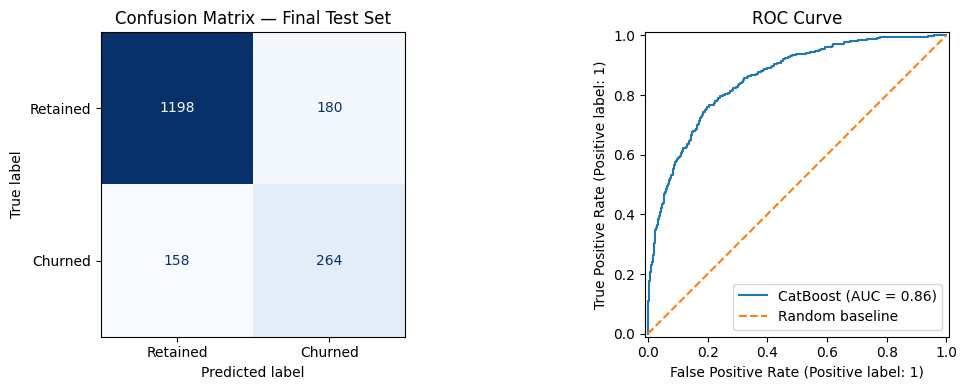

Confusion matrix (rows = actual; columns = predicted):
[[1198  180]
 [ 158  264]]


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions,
    display_labels=["Retained", "Churned"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion Matrix — Final Test Set")
RocCurveDisplay.from_predictions(y_test, test_probabilities, name=best_model_name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
axes[1].set_title("ROC Curve")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Confusion matrix (rows = actual; columns = predicted):")
print(confusion_matrix(y_test, test_predictions))

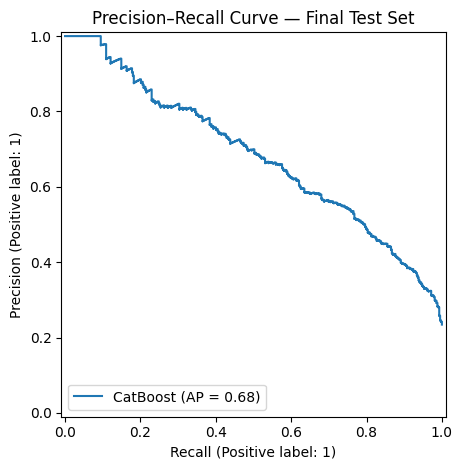

Test churn prevalence / no-skill PR baseline: 0.2344
Model PR-AUC: 0.6838


In [11]:
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, name=best_model_name)
plt.title("Precision–Recall Curve — Final Test Set")
plt.tight_layout()
plt.show()
print("Test churn prevalence / no-skill PR baseline: {:.4f}".format(y_test.mean()))
print("Model PR-AUC: {:.4f}".format(average_precision_score(y_test, test_probabilities)))

## 10. Explain the model: feature importance
CatBoost feature importance indicates which input variables the fitted model relied on most. Importance is predictive, not causal.

TOP 15 MODEL DRIVERS


,Feature,Importance
5,customer_satisfaction,24.6610
3,support_tickets,14.9243
2,contract_type,10.9970
4,late_payments,9.8038
0,tenure_months,8.9258
7,monthly_usage_hours,7.6857
6,service_downtime_hours,6.8867
10,active_addon_count,6.3448
8,usage_decline_flag,3.9441
9,autopay_enabled,3.2744


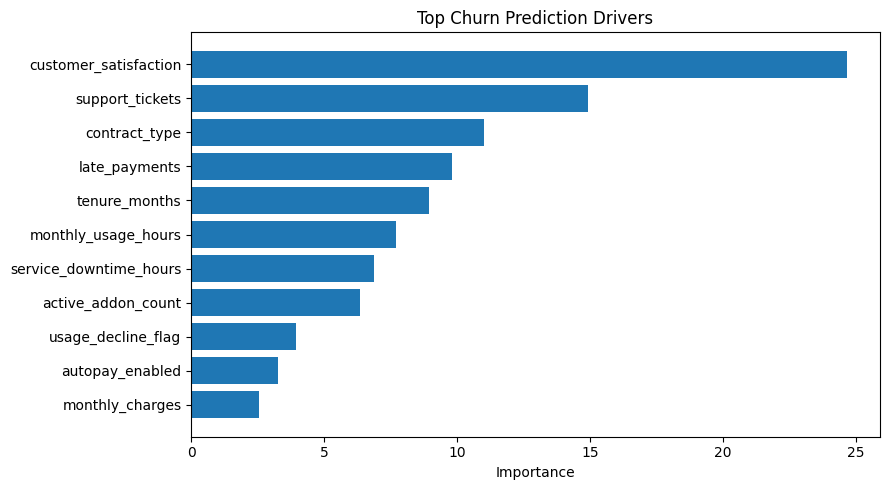

In [12]:
if best_model_name == "CatBoost":
    importance_values = best_model.get_feature_importance()
    importance_names = X.columns
else:
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_estimator = best_model.named_steps["model"]
    importance_values = fitted_estimator.feature_importances_ if hasattr(fitted_estimator, "feature_importances_") else np.abs(fitted_estimator.coef_[0])
    importance_names = fitted_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({"Feature": importance_names, "Importance": importance_values}).sort_values("Importance", ascending=False)
print("TOP 15 MODEL DRIVERS")
display(feature_importance.head(15).round(4))

plot_importance = feature_importance.head(12).sort_values("Importance")
plt.figure(figsize=(9, 5))
plt.barh(plot_importance["Feature"].astype(str), plot_importance["Importance"])
plt.xlabel("Importance")
plt.title("Top Churn Prediction Drivers")
plt.tight_layout()
plt.show()

## 11. Score the customer base and create risk groups
The model scores the full simulated customer base to demonstrate how a retention team could prioritise outreach. Risk categories are illustrative operational bands and should be calibrated to campaign capacity and costs.

In [13]:
scored_data = data.copy()
scored_features = scored_data.drop(columns=["customer_id", "churn"])
scored_data["churn_probability"] = best_model.predict_proba(scored_features)[:, 1]
scored_data["churn_probability_pct"] = (scored_data["churn_probability"] * 100).round(2)

# Use practical risk bands for the simulated customer base.
scored_data["risk_category"] = pd.cut(
    scored_data["churn_probability"],
    bins=[-np.inf, 0.25, 0.50, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

risk_summary = scored_data["risk_category"].value_counts().reindex(["High Risk", "Medium Risk", "Low Risk"], fill_value=0).to_frame("Customers")
risk_summary["Percentage"] = (risk_summary["Customers"] / len(scored_data) * 100).round(2)
print("CUSTOMER RISK DISTRIBUTION")
display(risk_summary)
print("SAMPLE CUSTOMER SCORES")
display(scored_data[["customer_id", "churn_probability_pct", "risk_category"]].head(10))

CUSTOMER RISK DISTRIBUTION


,Customers,Percentage
risk_category,,
High Risk,1879,15.66
Medium Risk,2175,18.12
Low Risk,7946,66.22


SAMPLE CUSTOMER SCORES


,customer_id,churn_probability_pct,risk_category
0,TEL000001,60.53,High Risk
1,TEL000002,3.18,Low Risk
2,TEL000003,33.11,Medium Risk
3,TEL000004,37.16,Medium Risk
4,TEL000005,39.66,Medium Risk
5,TEL000006,3.10,Low Risk
6,TEL000007,5.93,Low Risk
7,TEL000008,6.60,Low Risk
8,TEL000009,12.60,Low Risk
9,TEL000010,8.71,Low Risk


## 12. Recommend retention actions and prioritise customers

In [14]:
def recommend_action(row):
    if row["risk_category"] == "High Risk" and row["support_tickets"] >= 3:
        return "Priority service recovery call"
    if row["risk_category"] == "High Risk" and row["late_payments"] >= 2:
        return "Billing support and payment plan review"
    if row["risk_category"] == "High Risk":
        return "Personalised retention offer"
    if row["risk_category"] == "Medium Risk":
        return "Engagement and satisfaction check-in"
    return "Standard service; monitor"

scored_data["recommended_action"] = scored_data.apply(recommend_action, axis=1)
# Expected annual recurring charge exposure proxy; not a prediction of recoverable revenue.
scored_data["estimated_annual_charge_exposure"] = (
    scored_data["monthly_charges"] * 12 * scored_data["churn_probability"]
).round(2)
scored_data["retention_priority_score"] = scored_data["estimated_annual_charge_exposure"]

priority_customers = scored_data.sort_values("retention_priority_score", ascending=False)
print("TOP 15 CUSTOMERS FOR RETENTION REVIEW")
display(priority_customers[[
    "customer_id", "churn_probability_pct", "risk_category", "monthly_charges",
    "estimated_annual_charge_exposure", "recommended_action"
]].head(15).round(2))

print("\nRECOMMENDED ACTION COUNTS")
display(scored_data["recommended_action"].value_counts().to_frame("Customers"))

TOP 15 CUSTOMERS FOR RETENTION REVIEW


,customer_id,churn_probability_pct,risk_category,monthly_charges,estimated_annual_charge_exposure,recommended_action
6905,TEL006906,95.81,High Risk,125.00,1437.11,Priority service recovery call
6526,TEL006527,97.18,High Risk,122.86,1432.69,Billing support and payment plan review
3895,TEL003896,97.95,High Risk,121.44,1427.40,Priority service recovery call
216,TEL000217,91.91,High Risk,125.00,1378.70,Priority service recovery call
685,TEL000686,94.76,High Risk,120.20,1366.83,Billing support and payment plan review
8585,TEL008586,90.56,High Risk,125.00,1358.34,Priority service recovery call
4795,TEL004796,89.85,High Risk,125.00,1347.78,Priority service recovery call
7910,TEL007911,89.79,High Risk,125.00,1346.82,Priority service recovery call
6843,TEL006844,94.60,High Risk,118.61,1346.40,Priority service recovery call
11576,TEL011577,89.45,High Risk,125.00,1341.72,Billing support and payment plan review



RECOMMENDED ACTION COUNTS


,Customers
recommended_action,
Standard service; monitor,7946
Engagement and satisfaction check-in,2175
Personalised retention offer,801
Priority service recovery call,674
Billing support and payment plan review,404


## 13. Executive business summary

In [15]:
total_customers = len(scored_data)
risk_counts = scored_data["risk_category"].value_counts()
high_risk = int(risk_counts.get("High Risk", 0))
medium_risk = int(risk_counts.get("Medium Risk", 0))
low_risk = int(risk_counts.get("Low Risk", 0))

print("=" * 62)
print("SMART CUSTOMER CHURN & RETENTION — EXECUTIVE SUMMARY")
print("=" * 62)
print(f"Customers scored                  : {total_customers:,}")
print(f"High-risk customers               : {high_risk:,} ({high_risk/total_customers:.1%})")
print(f"Medium-risk customers             : {medium_risk:,} ({medium_risk/total_customers:.1%})")
print(f"Low-risk customers                : {low_risk:,} ({low_risk/total_customers:.1%})")
print(f"Average predicted churn probability: {scored_data['churn_probability'].mean():.1%}")
print(f"Annual charge exposure proxy      : {scored_data['estimated_annual_charge_exposure'].sum():,.2f}")
print(f"Selected model                    : {best_model_name}")
print(f"Decision threshold                : {best_threshold:.3f}")
print("=" * 62)
print("\nHOLD-OUT MODEL METRICS")
for metric, value in test_metrics.items():
    print(f"{metric:12s}: {value:.4f}")

SMART CUSTOMER CHURN & RETENTION — EXECUTIVE SUMMARY
Customers scored                  : 12,000
High-risk customers               : 1,879 (15.7%)
Medium-risk customers             : 2,175 (18.1%)
Low-risk customers                : 7,946 (66.2%)
Average predicted churn probability: 23.3%
Annual charge exposure proxy      : 2,602,387.50
Selected model                    : CatBoost
Decision threshold                : 0.355

HOLD-OUT MODEL METRICS
Accuracy    : 0.8122
Precision   : 0.5946
Recall      : 0.6256
F1 Score    : 0.6097
ROC-AUC     : 0.8554
PR-AUC      : 0.6838


## 14. Export customer-level results for Power BI
The CSV contains simulated customer attributes, churn label, predicted probability, risk band, recommended action and a charge-exposure proxy.

In [16]:
output_file = "customer_retention_predictions.csv"
scored_data.to_csv(output_file, index=False)
print("Exported:", output_file)
print("Rows:", len(scored_data))
print("Columns:", len(scored_data.columns))
display(pd.read_csv(output_file).head())

Exported: customer_retention_predictions.csv
Rows: 12000
Columns: 19


,customer_id,tenure_months,monthly_charges,contract_type,support_tickets,late_payments,customer_satisfaction,service_downtime_hours,monthly_usage_hours,usage_decline_flag,autopay_enabled,active_addon_count,churn,churn_probability,churn_probability_pct,risk_category,recommended_action,estimated_annual_charge_exposure,retention_priority_score
0,TEL000001,7,52.08,Month-to-month,2,0,5.3,7.68,115.9,0,1,6,1,0.605317,60.53,High Risk,Personalised retention offer,378.30,378.30
1,TEL000002,56,90.07,One year,0,0,6.9,1.21,134.3,1,1,2,0,0.031790,3.18,Low Risk,Standard service; monitor,34.36,34.36
2,TEL000003,48,62.81,Month-to-month,1,1,9.6,9.32,64.7,1,1,5,1,0.331073,33.11,Medium Risk,Engagement and satisfaction check-in,249.54,249.54
3,TEL000004,32,36.77,Month-to-month,2,0,5.3,1.55,96.4,0,1,2,0,0.371624,37.16,Medium Risk,Engagement and satisfaction check-in,163.98,163.98
4,TEL000005,32,70.81,One year,2,0,5.1,2.36,77.3,0,1,0,0,0.396647,39.66,Medium Risk,Engagement and satisfaction check-in,337.04,337.04


## 15. Conclusion and limitations
This version demonstrates a more complete churn workflow with a larger dataset, validation-based model selection, a recall-aware decision threshold and customer-level retention prioritisation.

**Interpretation:** Accuracy, precision and recall measure different things. In churn work, recall is important because missed churners are customers the retention team cannot target. Precision matters because false alarms consume campaign resources. The selected threshold balances these objectives under the stated validation rule.

**Limitations:** The data is simulated and intentionally contains learnable churn signals. The reported test metrics are valid only for this synthetic simulation and must not be represented as real-world benchmark results. Feature importance is not causal. The annual charge exposure is a prioritisation proxy, not expected recovered revenue. Before deployment, validate with historical customer data, time-based splits, cost-sensitive thresholds, fairness checks and drift monitoring.